In [7]:
# TAHAP 0: Setup
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# konstanta
AMBANG = 55            # ambang PM2.5 hari tinggi (requirement)
MIN_EPISODE = 3        # minimal hari berturut-turut = 1 episode
DAFTAR_K = range(2, 7) # k = 2 sampai 6
RANDOM_STATE = 42
FILE_DATA = "../../data/data_gabungan/airguard_harian_kualitas_udara_jawa.csv"

# buat folder keluaran (kalau sudah ada, tidak error)
os.makedirs("data/data_gabungan", exist_ok=True)
os.makedirs("models", exist_ok=True)

daftar_fitur = [
    "rata_rata_pm25", "median_pm25", "maksimum_pm25", "standar_deviasi_pm25",
    "persentase_hari_tinggi", "jumlah_episode", "durasi_episode_terpanjang",
    "rata_rata_pm10", "rata_rata_nitrogen_dioxide", "rata_rata_carbon_monoxide",
]
print("Setup selesai, jumlah fitur clustering:", len(daftar_fitur))

Setup selesai, jumlah fitur clustering: 10


In [8]:
# TAHAP 1: Muat dan validasi data
df = pd.read_csv(FILE_DATA)
df["tanggal"] = pd.to_datetime(df["tanggal"])
df = df.sort_values(["nama_kabkota", "tanggal"]).reset_index(drop=True)

print("Ukuran data:", df.shape)
print("Rentang tanggal:", df["tanggal"].min().date(), "sampai", df["tanggal"].max().date())

# --- gate: harus sama dengan KARAKTERISTIK_DATASET_JAWA.md ---
assert df.shape == (183379, 16), "Jumlah baris/kolom tidak sesuai"
assert df["nama_kabkota"].nunique() == 119, "Jumlah wilayah bukan 119"

hari_per_wilayah = df.groupby("nama_kabkota")["tanggal"].count()
assert (hari_per_wilayah == 1541).all(), "Ada wilayah yang jumlah harinya bukan 1541"

assert df.isna().sum().sum() == 0, "Ada nilai kosong"
assert not df.duplicated(["nama_kabkota", "tanggal"]).any(), "Ada duplikat wilayah-tanggal"

selisih_tanggal = df.groupby("nama_kabkota")["tanggal"].diff().dropna()
assert (selisih_tanggal == pd.Timedelta(days=1)).all(), "Ada tanggal yang bolong"
print("Semua pengecekan struktur data LOLOS")

# --- catatan grid untuk dashboard: berapa deret PM2.5 yang benar-benar unik? ---
tabel_pm25 = df.pivot(index="tanggal", columns="nama_kabkota", values="pm2_5")
jumlah_deret_unik = tabel_pm25.T.round(4).drop_duplicates().shape[0]
print("Jumlah deret PM2.5 unik dari 119 wilayah:", jumlah_deret_unik)

Ukuran data: (183379, 16)
Rentang tanggal: 2022-08-04 sampai 2026-10-22
Semua pengecekan struktur data LOLOS
Jumlah deret PM2.5 unik dari 119 wilayah: 63


In [9]:
# TAHAP 2: Ringkas data harian menjadi 1 baris per wilayah
def hitung_episode(deret_pm25):
    # episode = minimal MIN_EPISODE hari berturut-turut dengan PM2.5 > AMBANG
    jumlah_episode = 0
    durasi_terpanjang = 0
    panjang_sekarang = 0   # panjang rentetan hari tinggi yang sedang berjalan
    for nilai in deret_pm25:
        if nilai > AMBANG:
            panjang_sekarang += 1
        else:
            # rentetan putus, cek apakah cukup panjang jadi episode
            if panjang_sekarang >= MIN_EPISODE:
                jumlah_episode += 1
                durasi_terpanjang = max(durasi_terpanjang, panjang_sekarang)
            panjang_sekarang = 0
    # rentetan yang masih berjalan sampai hari terakhir
    if panjang_sekarang >= MIN_EPISODE:
        jumlah_episode += 1
        durasi_terpanjang = max(durasi_terpanjang, panjang_sekarang)
    return jumlah_episode, durasi_terpanjang

# statistik dasar per wilayah (kolom identitas ikut dibawa sebagai label)
ringkasan = df.groupby("nama_kabkota").agg(
    provinsi=("provinsi", "first"),
    kode_kabkota=("kode_kabkota", "first"),
    latitude=("latitude", "first"),
    longitude=("longitude", "first"),
    rata_rata_pm25=("pm2_5", "mean"),
    median_pm25=("pm2_5", "median"),
    maksimum_pm25=("pm2_5", "max"),
    standar_deviasi_pm25=("pm2_5", "std"),
    persentase_hari_tinggi=("pm2_5", lambda x: (x > AMBANG).mean() * 100),
    rata_rata_pm10=("pm10", "mean"),
    rata_rata_nitrogen_dioxide=("nitrogen_dioxide", "mean"),
    rata_rata_carbon_monoxide=("carbon_monoxide", "mean"),
).reset_index()

# fitur episode dihitung per wilayah dari deret harian (sudah terurut tanggal)
daftar_jumlah_episode = []
daftar_durasi_terpanjang = []
for nama in ringkasan["nama_kabkota"]:
    deret = df.loc[df["nama_kabkota"] == nama, "pm2_5"].values
    jumlah, durasi = hitung_episode(deret)
    daftar_jumlah_episode.append(jumlah)
    daftar_durasi_terpanjang.append(durasi)

ringkasan["jumlah_episode"] = daftar_jumlah_episode
ringkasan["durasi_episode_terpanjang"] = daftar_durasi_terpanjang

# --- gate ---
assert ringkasan.shape[0] == 119, "Baris ringkasan bukan 119"
assert ringkasan[daftar_fitur].isna().sum().sum() == 0, "Ada NaN di fitur"
assert np.isfinite(ringkasan[daftar_fitur].values).all(), "Ada inf di fitur"
assert ringkasan["persentase_hari_tinggi"].between(0, 100).all(), "Persentase di luar 0-100"
print("Ringkasan:", ringkasan.shape, "-> LOLOS")

print("\nStatistik deskriptif fitur:")
print(ringkasan[daftar_fitur].describe().round(2))

print("\nKorelasi antar fitur:")
print(ringkasan[daftar_fitur].corr().round(2))

Ringkasan: (119, 15) -> LOLOS

Statistik deskriptif fitur:
       rata_rata_pm25  median_pm25  maksimum_pm25  standar_deviasi_pm25  \
count          119.00       119.00         119.00                119.00   
mean            37.04        33.69         115.85                 17.66   
std             13.15        13.56          26.37                  5.38   
min             13.83        11.38          49.28                  6.35   
25%             27.35        24.70          94.47                 13.66   
50%             36.62        31.66         124.07                 18.74   
75%             42.76        38.97         133.63                 21.76   
max             67.20        68.19         159.68                 27.65   

       persentase_hari_tinggi  jumlah_episode  durasi_episode_terpanjang  \
count                  119.00          119.00                     119.00   
mean                    19.64           29.51                      30.97   
std                     18.71        

In [10]:
# TAHAP 3: Uji kewajaran terhadap angka acuan KARAKTERISTIK_DATASET_JAWA.md
masalah = []   # kumpulan selisih besar

# 1. rata-rata PM2.5 keseluruhan (acuan 37.04)
rata_keseluruhan = df["pm2_5"].mean()
print("Rata-rata PM2.5 keseluruhan:", round(rata_keseluruhan, 2), "(acuan 37.04)")
if abs(rata_keseluruhan - 37.04) > 0.1:
    masalah.append("Rata-rata keseluruhan menyimpang dari 37.04")

# 2. lima wilayah tertinggi (acuan rata-rata sekitar 67.20)
urut = ringkasan.sort_values("rata_rata_pm25", ascending=False)
lima_tertinggi = urut.head(5)
print("\n5 wilayah tertinggi:")
print(lima_tertinggi[["nama_kabkota", "provinsi", "rata_rata_pm25"]].round(2))
rata_lima_tertinggi = lima_tertinggi["rata_rata_pm25"].mean()
print("Rata-rata 5 tertinggi:", round(rata_lima_tertinggi, 2), "(acuan ~67.20)")
if abs(rata_lima_tertinggi - 67.20) > 1:
    masalah.append("Rata-rata 5 tertinggi menyimpang dari ~67.20")

teks_tertinggi = " ".join(lima_tertinggi["nama_kabkota"])
for kata in ["Depok", "Tangerang Selatan", "Jakarta Selatan", "Jakarta Timur", "Bekasi"]:
    if kata not in teks_tertinggi:
        masalah.append("Wilayah " + kata + " tidak masuk 5 tertinggi")

# 3. lima wilayah terendah (acuan di bawah 17)
lima_terendah = urut.tail(5)
print("\n5 wilayah terendah:")
print(lima_terendah[["nama_kabkota", "provinsi", "rata_rata_pm25"]].round(2))
if not (lima_terendah["rata_rata_pm25"] < 17).all():
    masalah.append("Ada wilayah 5 terendah yang nilainya >= 17")

teks_terendah = " ".join(lima_terendah["nama_kabkota"])
for kata in ["Sumenep", "Kulon Progo", "Situbondo", "Pamekasan", "Banyuwangi"]:
    if kata not in teks_terendah:
        masalah.append("Wilayah " + kata + " tidak masuk 5 terendah")

# 4. rata-rata per provinsi
acuan_provinsi = {
    "DKI Jakarta": 50.54, "Banten": 46.12, "Jawa Barat": 45.14,
    "Jawa Tengah": 34.79, "Jawa Timur": 30.67, "DI Yogyakarta": 26.78,
}
rata_provinsi = df.groupby("provinsi")["pm2_5"].mean()
print("\nRata-rata PM2.5 per provinsi (hitungan vs acuan):")
for nama_prov, nilai_acuan in acuan_provinsi.items():
    if nama_prov in rata_provinsi.index:
        nilai_hitung = rata_provinsi[nama_prov]
        print(" ", nama_prov, ":", round(nilai_hitung, 2), "vs", nilai_acuan)
        if abs(nilai_hitung - nilai_acuan) > 0.1:
            masalah.append("Provinsi " + nama_prov + " menyimpang dari acuan")
    else:
        masalah.append("Nama provinsi '" + nama_prov + "' tidak ada di data, cek penulisan")
print("Nama provinsi di data:", list(rata_provinsi.index))

# --- hasil uji kewajaran ---
if len(masalah) == 0:
    print("\nUji kewajaran LOLOS, perhitungan sesuai angka acuan")
else:
    print("\nPERINGATAN, ada selisih dari angka acuan (kemungkinan salah hitung):")
    for m in masalah:
        print(" -", m)

Rata-rata PM2.5 keseluruhan: 37.04 (acuan 37.04)

5 wilayah tertinggi:
                          nama_kabkota     provinsi  rata_rata_pm25
99                          Kota Depok   Jawa Barat            67.2
115             Kota Tangerang Selatan       Banten            67.2
87   Kota Administrasi Jakarta Selatan  DKI Jakarta            67.2
88     Kota Administrasi Jakarta Timur  DKI Jakarta            67.2
93                         Kota Bekasi   Jawa Barat            67.2
Rata-rata 5 tertinggi: 67.2 (acuan ~67.20)

5 wilayah terendah:
             nama_kabkota       provinsi  rata_rata_pm25
7    Kabupaten Banyuwangi     Jawa Timur           16.52
51    Kabupaten Pamekasan     Jawa Timur           16.48
68    Kabupaten Situbondo     Jawa Timur           16.05
37  Kabupaten Kulon Progo  DI Yogyakarta           15.59
75      Kabupaten Sumenep     Jawa Timur           13.83

Rata-rata PM2.5 per provinsi (hitungan vs acuan):
  DKI Jakarta : 50.54 vs 50.54
  Banten : 46.12 vs 46.12
  Jawa 

In [11]:
# TAHAP 4: Standardisasi fitur (StandardScaler)
X = ringkasan[daftar_fitur]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Ukuran X_scaled:", X_scaled.shape)
print("Mean tiap fitur:", X_scaled.mean(axis=0).round(6))
print("Std tiap fitur :", X_scaled.std(axis=0).round(6))

# --- gate ---
assert X_scaled.shape == (119, 10), "Ukuran bukan 119 x 10"
assert np.allclose(X_scaled.mean(axis=0), 0, atol=1e-6), "Mean belum mendekati 0"
assert np.allclose(X_scaled.std(axis=0), 1, atol=1e-6), "Std belum mendekati 1"
print("Standardisasi LOLOS")

Ukuran X_scaled: (119, 10)
Mean tiap fitur: [-0.  0. -0. -0.  0. -0.  0.  0.  0.  0.]
Std tiap fitur : [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Standardisasi LOLOS


c:\Users\NAUFAL\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\NAUFAL\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\NAUFAL\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 546, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\NAUFAL\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1022, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds

   k   inertia  silhouette  ukuran_cluster_terkecil
0  2  510.8485      0.5411                       28
1  3  276.9616      0.4777                       20
2  4  187.0867      0.5021                        7
3  5  149.8707      0.5199                        4
4  6  116.3137      0.4424                        4


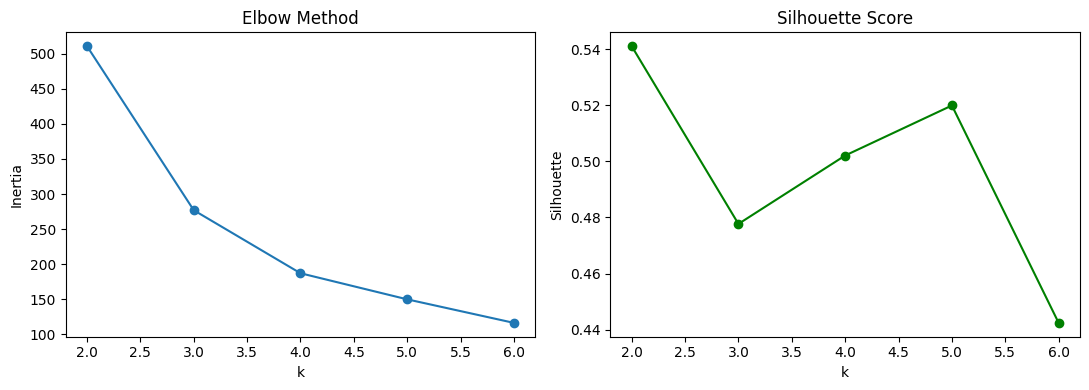


k dengan silhouette terbaik: 2
Selisih silhouette k=3 dari yang terbaik: 0.0634
Ukuran cluster terkecil pada k=3: 20
-> TANDA: k=3 TIDAK memenuhi aturan. Putuskan sendiri, lalu isi K_FINAL manual di cell berikutnya.


In [12]:
# TAHAP 5: Pilih jumlah cluster (k = 2 sampai 6)
hasil_k = []
for k in DAFTAR_K:
    model_k = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    label_k = model_k.fit_predict(X_scaled)
    hasil_k.append({
        "k": k,
        "inertia": model_k.inertia_,
        "silhouette": silhouette_score(X_scaled, label_k),
        "ukuran_cluster_terkecil": np.bincount(label_k).min(),
    })
tabel_k = pd.DataFrame(hasil_k)
print(tabel_k.round(4))

# plot Elbow dan Silhouette
gambar, sumbu = plt.subplots(1, 2, figsize=(11, 4))
sumbu[0].plot(tabel_k["k"], tabel_k["inertia"], marker="o")
sumbu[0].set_title("Elbow Method")
sumbu[0].set_xlabel("k")
sumbu[0].set_ylabel("Inertia")
sumbu[1].plot(tabel_k["k"], tabel_k["silhouette"], marker="o", color="green")
sumbu[1].set_title("Silhouette Score")
sumbu[1].set_xlabel("k")
sumbu[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()

# --- aturan pemilihan k (default no. 3) ---
silhouette_terbaik = tabel_k["silhouette"].max()
k_terbaik = int(tabel_k.loc[tabel_k["silhouette"].idxmax(), "k"])
baris_k3 = tabel_k[tabel_k["k"] == 3].iloc[0]
selisih_silhouette = silhouette_terbaik - baris_k3["silhouette"]

print("\nk dengan silhouette terbaik:", k_terbaik)
print("Selisih silhouette k=3 dari yang terbaik:", round(selisih_silhouette, 4))
print("Ukuran cluster terkecil pada k=3:", int(baris_k3["ukuran_cluster_terkecil"]))

if selisih_silhouette <= 0.05 and baris_k3["ukuran_cluster_terkecil"] >= 5:
    K_FINAL = 3
    print("-> k=3 memenuhi aturan, K_FINAL = 3")
else:
    K_FINAL = None
    print("-> TANDA: k=3 TIDAK memenuhi aturan. Putuskan sendiri, lalu isi K_FINAL manual di cell berikutnya.")

In [14]:
# TAHAP 6: Fit K-Means final, label diurutkan berdasarkan rata_rata_pm25
# Kalau Cell 6 menandai k=3 tidak memenuhi aturan, hapus tanda # di bawah dan isi sendiri:
K_FINAL = 3
assert K_FINAL is not None, "K_FINAL belum ditentukan, isi manual dulu"

model_final = KMeans(n_clusters=K_FINAL, n_init=10, random_state=RANDOM_STATE)
label_asli = model_final.fit_predict(X_scaled)
ringkasan["label_asli"] = label_asli

# urutkan label lama berdasarkan rata-rata PM2.5 cluster (terendah = 0)
rata_pm25_per_label = ringkasan.groupby("label_asli")["rata_rata_pm25"].mean().sort_values()
mapping_label = {}
nomor_baru = 0
for label_lama in rata_pm25_per_label.index:
    mapping_label[int(label_lama)] = nomor_baru
    nomor_baru += 1
print("Mapping label (lama -> baru):", mapping_label)

ringkasan["cluster"] = ringkasan["label_asli"].map(mapping_label)

# --- gate: tiap cluster minimal 5 wilayah ---
ukuran_cluster = ringkasan["cluster"].value_counts().sort_index()
print("\nJumlah wilayah per cluster:")
print(ukuran_cluster)
assert ukuran_cluster.min() >= 5, "Ada cluster dengan wilayah kurang dari 5"
print("Fit final LOLOS")

Mapping label (lama -> baru): {2: 0, 0: 1, 1: 2}

Jumlah wilayah per cluster:
cluster
0    49
1    50
2    20
Name: count, dtype: int64
Fit final LOLOS


Jumlah wilayah per cluster:
cluster
0    49
1    50
2    20
Name: count, dtype: int64

Rata-rata fitur per cluster:
cluster                          0       1        2
rata_rata_pm25               25.42   39.74    58.78
median_pm25                  22.75   34.93    57.40
maksimum_pm25                90.28  130.32   142.34
standar_deviasi_pm25         12.19   20.92    22.92
persentase_hari_tinggi        3.60   22.18    52.58
jumlah_episode                5.84   38.66    64.65
durasi_episode_terpanjang     4.35   30.50    97.40
rata_rata_pm10               31.40   47.15    71.90
rata_rata_nitrogen_dioxide   10.48   18.02    47.80
rata_rata_carbon_monoxide   425.51  594.43  1521.75

Sebaran provinsi per cluster:
cluster         0   1   2
provinsi                 
Banten          0   4   4
DI Yogyakarta   3   2   0
DKI Jakarta     1   0   5
Jawa Barat      7   9  11
Jawa Tengah    13  22   0
Jawa Timur     25  13   0

Anggota cluster 0 ( 49 wilayah ):
Kabupaten Sumenep, Kabupaten Kulon Pro

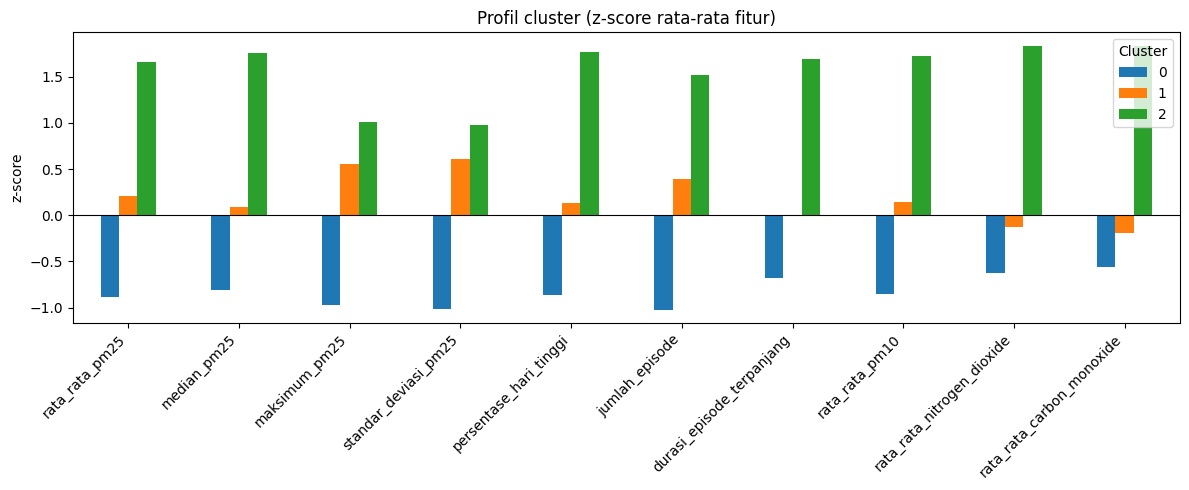

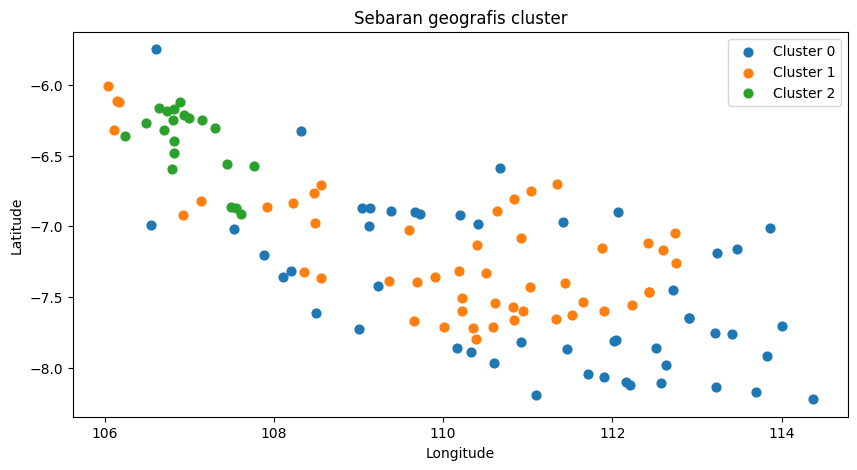


Nama cluster (sementara):
cluster  nama_cluster    
0        rendah-stabil       49
1        sedang-musiman      50
2        tinggi-persisten    20
dtype: int64


In [15]:
# TAHAP 7: Profil cluster
# 1. jumlah wilayah per cluster
print("Jumlah wilayah per cluster:")
print(ringkasan["cluster"].value_counts().sort_index())

# 2. rata-rata 10 fitur per cluster
profil_cluster = ringkasan.groupby("cluster")[daftar_fitur].mean()
print("\nRata-rata fitur per cluster:")
print(profil_cluster.round(2).T)

# 3. sebaran provinsi per cluster
print("\nSebaran provinsi per cluster:")
print(pd.crosstab(ringkasan["provinsi"], ringkasan["cluster"]))

# 4. daftar anggota tiap cluster
for nomor in sorted(ringkasan["cluster"].unique()):
    anggota = ringkasan.loc[ringkasan["cluster"] == nomor].sort_values("rata_rata_pm25")
    print("\nAnggota cluster", nomor, "(", len(anggota), "wilayah ):")
    print(", ".join(anggota["nama_kabkota"]))

# 5. bar chart profil (z-score rata-rata tiap cluster)
profil_z = pd.DataFrame(X_scaled, columns=daftar_fitur)
profil_z["cluster"] = ringkasan["cluster"].values
profil_z = profil_z.groupby("cluster")[daftar_fitur].mean()
profil_z.T.plot(kind="bar", figsize=(12, 5))
plt.title("Profil cluster (z-score rata-rata fitur)")
plt.ylabel("z-score")
plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=45, ha="right")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

# 6. scatter lon-lat untuk cek sebaran geografis
plt.figure(figsize=(10, 5))
for nomor in sorted(ringkasan["cluster"].unique()):
    bagian = ringkasan[ringkasan["cluster"] == nomor]
    plt.scatter(bagian["longitude"], bagian["latitude"], label="Cluster " + str(nomor), s=40)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Sebaran geografis cluster")
plt.legend()
plt.show()

# 7. nama cluster: ini USULAN AWAL dari requirement.
# Ubah isi kamus ini setelah melihat profil di atas dan setelah kamu setuju.
NAMA_CLUSTER = {
    0: "rendah-stabil",
    1: "sedang-musiman",
    2: "tinggi-persisten",
}
ringkasan["nama_cluster"] = ringkasan["cluster"].map(NAMA_CLUSTER)
ringkasan["nama_cluster"] = ringkasan["nama_cluster"].fillna("belum diberi nama")
print("\nNama cluster (sementara):")
print(ringkasan.groupby(["cluster", "nama_cluster"]).size())

Rata-rata PM2.5 per bulan per cluster:
cluster      0      1      2
bulan                       
1        25.36  37.27  38.76
2        25.98  38.08  41.83
3        27.69  41.96  46.36
4        25.55  40.06  57.71
5        25.49  41.05  67.16
6        26.67  45.39  71.32
7        22.40  39.00  69.03
8        22.69  36.52  67.41
9        22.94  36.78  66.04
10       25.63  38.40  65.66
11       28.90  42.60  58.83
12       27.00  41.48  49.39
Cluster 0 -> amplitudo musiman: 25.5 % | bulan puncak: 11 | bulan terendah: 7
Cluster 1 -> amplitudo musiman: 22.2 % | bulan puncak: 6 | bulan terendah: 8
Cluster 2 -> amplitudo musiman: 55.9 % | bulan puncak: 6 | bulan terendah: 1


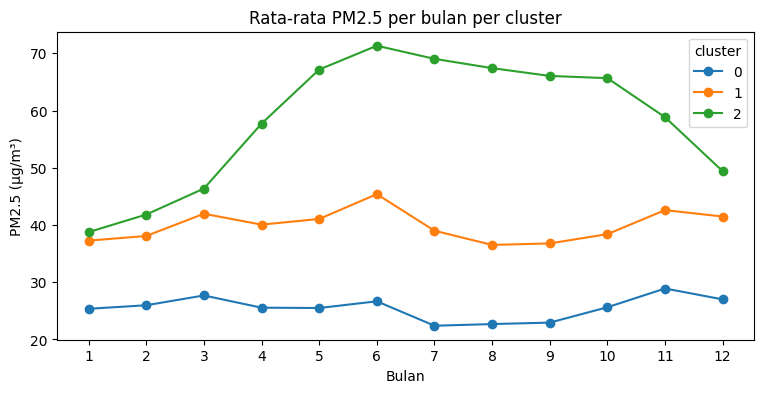


Rata-rata silhouette per cluster:
cluster
0    0.522
1    0.490
2    0.336
Name: silhouette_wilayah, dtype: float64

10 wilayah dengan silhouette terendah (paling dekat batas cluster):
              nama_kabkota     provinsi  cluster  silhouette_wilayah
40         Kabupaten Lebak       Banten        2              -0.072
76     Kabupaten Tangerang       Banten        2              -0.027
32       Kabupaten Kebumen  Jawa Tengah        1               0.006
71        Kabupaten Subang   Jawa Barat        2               0.024
62     Kabupaten Purworejo  Jawa Tengah        1               0.025
67      Kabupaten Sidoarjo   Jawa Timur        0               0.047
61    Kabupaten Purwakarta   Jawa Barat        2               0.065
105          Kota Pasuruan   Jawa Timur        0               0.096
54      Kabupaten Pasuruan   Jawa Timur        0               0.096
77   Kabupaten Tasikmalaya   Jawa Barat        0               0.160


In [16]:
# TAHAP 7b: Pemeriksaan tambahan sebelum nama cluster difinalkan
from sklearn.metrics import silhouette_samples

# 1. pola PM2.5 per bulan untuk tiap cluster (bukti "musiman")
df_cluster = df.merge(ringkasan[["nama_kabkota", "cluster"]], on="nama_kabkota")
df_cluster["bulan"] = df_cluster["tanggal"].dt.month
pola_bulanan = df_cluster.groupby(["cluster", "bulan"])["pm2_5"].mean().unstack(0)
print("Rata-rata PM2.5 per bulan per cluster:")
print(pola_bulanan.round(2))

# amplitudo musiman = (bulan tertinggi - bulan terendah) / rata-rata cluster
for nomor in pola_bulanan.columns:
    nilai = pola_bulanan[nomor]
    amplitudo = (nilai.max() - nilai.min()) / nilai.mean() * 100
    print("Cluster", nomor, "-> amplitudo musiman:", round(amplitudo, 1), "%",
          "| bulan puncak:", nilai.idxmax(), "| bulan terendah:", nilai.idxmin())

pola_bulanan.plot(marker="o", figsize=(9, 4))
plt.title("Rata-rata PM2.5 per bulan per cluster")
plt.xlabel("Bulan")
plt.ylabel("PM2.5 (µg/m³)")
plt.xticks(range(1, 13))
plt.show()

# 2. silhouette per wilayah (cari wilayah yang batasnya tipis)
ringkasan["silhouette_wilayah"] = silhouette_samples(X_scaled, ringkasan["label_asli"])
print("\nRata-rata silhouette per cluster:")
print(ringkasan.groupby("cluster")["silhouette_wilayah"].mean().round(3))

print("\n10 wilayah dengan silhouette terendah (paling dekat batas cluster):")
print(ringkasan.sort_values("silhouette_wilayah").head(10)[
    ["nama_kabkota", "provinsi", "cluster", "silhouette_wilayah"]].round(3))

Variansi yang dijelaskan PC1: 84.0%, PC2: 9.0% (Total: 93.0%)


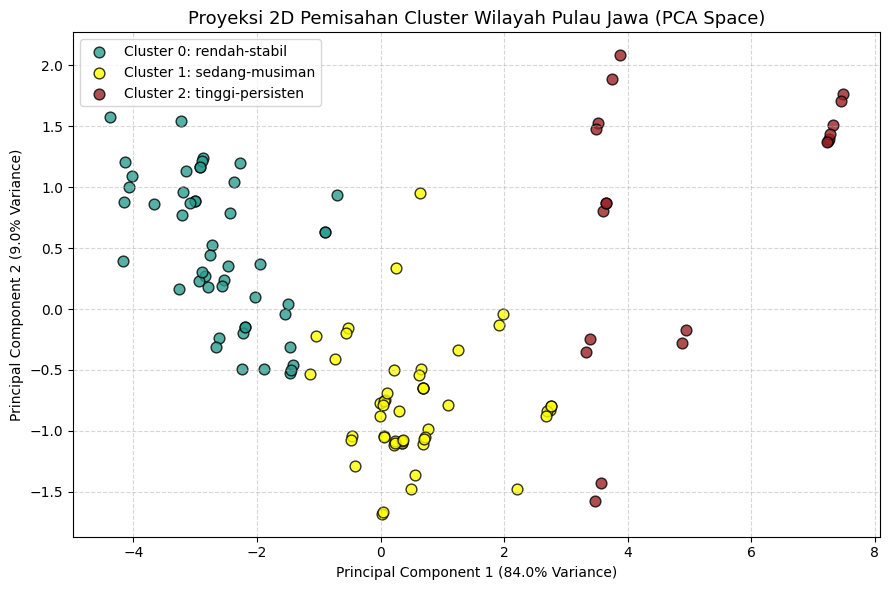

In [19]:
# TAHAP TAMBAHAN: Visualisasi Sebaran Cluster dengan PCA 2D (Untuk Storytelling)
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

var_exp = pca.explained_variance_ratio_ * 100
print(f"Variansi yang dijelaskan PC1: {var_exp[0]:.1f}%, PC2: {var_exp[1]:.1f}% (Total: {sum(var_exp):.1f}%)")

plt.figure(figsize=(9, 6))
warna_palet = {0: "#2A9D8F", 1: "#FFFF00", 2: "#9B2226"}
for c in sorted(ringkasan["cluster"].unique()):
    idx = ringkasan["cluster"] == c
    plt.scatter(
        X_pca[idx, 0], X_pca[idx, 1],
        label=f"Cluster {c}: {NAMA_CLUSTER[c]}",
        color=warna_palet[c], alpha=0.8, s=60, edgecolors="k"
    )

plt.title("Proyeksi 2D Pemisahan Cluster Wilayah Pulau Jawa (PCA Space)", fontsize=13)
plt.xlabel(f"Principal Component 1 ({var_exp[0]:.1f}% Variance)")
plt.ylabel(f"Principal Component 2 ({var_exp[1]:.1f}% Variance)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


In [20]:
# TAHAP 8: Simpan output dan verifikasi
kolom_keluaran = (
    ["nama_kabkota", "provinsi", "cluster", "nama_cluster",
     "kode_kabkota", "latitude", "longitude"] + daftar_fitur
)
hasil_clustering = ringkasan[kolom_keluaran]
hasil_clustering.to_csv("data/data_gabungan/clustering_wilayah.csv", index=False)

# simpan model + mapping label, dan scaler
joblib.dump(
    {"model": model_final, "mapping_label": mapping_label,
     "k": K_FINAL, "daftar_fitur": daftar_fitur},
    "models/kmeans_clustering.joblib",
)
joblib.dump(scaler, "models/scaler_clustering.joblib")
print("Semua file tersimpan")

# --- verifikasi: baca ulang semuanya ---
cek = pd.read_csv("data/data_gabungan/clustering_wilayah.csv")
paket_model = joblib.load("models/kmeans_clustering.joblib")
scaler_baca = joblib.load("models/scaler_clustering.joblib")

assert cek.shape[0] == 119, "Baris file bukan 119"
assert cek.isna().sum().sum() == 0, "Ada NaN di file keluaran"
for kolom in ["nama_kabkota", "provinsi", "cluster"] + daftar_fitur:
    assert kolom in cek.columns, "Kolom wajib hilang: " + kolom

# predict ulang dari model dan scaler yang disimpan
X_cek = scaler_baca.transform(cek[daftar_fitur])
label_prediksi = paket_model["model"].predict(X_cek)
cluster_prediksi = pd.Series(label_prediksi).map(paket_model["mapping_label"])
assert (cluster_prediksi.values == cek["cluster"].values).all(), "Label hasil predict beda dengan file"

print("Verifikasi LOLOS: 119 baris, tanpa NaN, predict ulang sama dengan file")
print(cek.head())

Semua file tersimpan
Verifikasi LOLOS: 119 baris, tanpa NaN, predict ulang sama dengan file
                              nama_kabkota     provinsi  cluster  \
0  Kabupaten Administrasi Kepulauan Seribu  DKI Jakarta        0   
1                        Kabupaten Bandung   Jawa Barat        0   
2                  Kabupaten Bandung Barat   Jawa Barat        2   
3                      Kabupaten Bangkalan   Jawa Timur        1   
4                   Kabupaten Banjarnegara  Jawa Tengah        1   

       nama_cluster  kode_kabkota  latitude   longitude  rata_rata_pm25  \
0     rendah-stabil         31.01 -5.746481  106.613160       19.053981   
1     rendah-stabil         32.04 -7.021855  107.527551       22.259732   
2  tinggi-persisten         32.17 -6.865221  107.491977       55.418193   
3    sedang-musiman         35.26 -7.046392  112.737067       37.945746   
4    sedang-musiman         33.04 -7.395695  109.696070       34.837614   

   median_pm25  maksimum_pm25  standar_deviasi_p